In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv('/content/placement.csv')

In [ ]:
df.head()


,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


In [ ]:
# even = ((n/2)+((n/2)+1))/2
# odd = ((n+1)/2)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df['resume_score'].describe()

,resume_score
count,100.000000
mean,6.930500
std,0.979608
min,4.950000
25%,6.190000
50%,7.055000
75%,7.640000
max,9.060000


<Axes: xlabel='resume_score'>

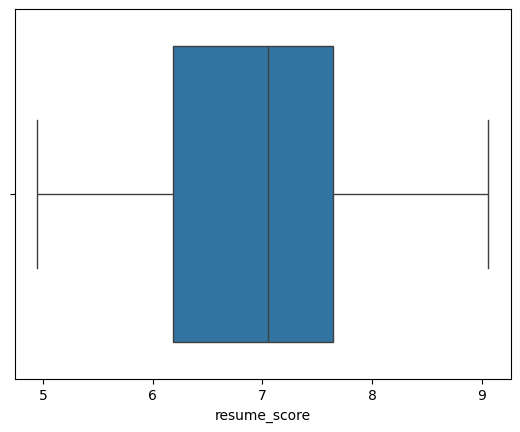

In [ ]:
sns.boxplot(x=df['resume_score'])

In [ ]:
# finding the IQR
percentile25 = df['resume_score'].quantile(0.25)
percentile75 = df['resume_score'].quantile(0.75)

In [ ]:
percentile25

np.float64(6.19)

In [ ]:
percentile75

np.float64(7.64)

In [ ]:
IQR = percentile75 - percentile25
IQR

np.float64(1.4499999999999993)

In [ ]:
upper_limit = percentile75 + 1.5*IQR
upper_limit

np.float64(9.814999999999998)

In [ ]:
lower_limit = percentile25 - 1.5*IQR
lower_limit

np.float64(4.0150000000000015)

# Finding Our Outliers

In [ ]:
df[df['resume_score']>upper_limit]

,cgpa,resume_score,placed


In [ ]:
df[df['resume_score']<lower_limit]

,cgpa,resume_score,placed


In [ ]:
# Trimming---> 4(lower).....1, upper(25).....(50) ----> here 1,50 are outliers --->
# lower(4) <------> upper(25) mid data


# capping ----> 4(lower)....1, upper(25).....(50) ----> capping lower point lowest point(1)
# upper point upper point(50) ---> Range expand ----> outliers remove

In [ ]:
# Trimming (Outlier Removing technique 1)

In [ ]:
newdf = df[df['resume_score']<upper_limit]

In [ ]:
newdf

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1
...,...,...,...
95,6.33,6.38,0
96,8.23,7.76,1
97,6.65,7.78,0
98,8.14,5.63,1


In [ ]:
#comparison

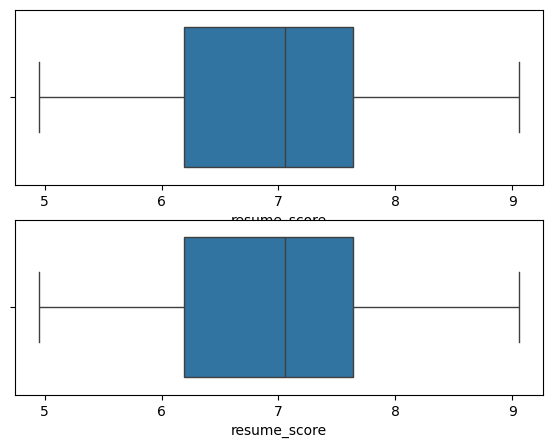

In [ ]:
plt.figure(figsize= (15,5))

plt.subplot(222)
sns.boxplot(x=df['resume_score'])

plt.subplot(224)
sns.boxplot(x=newdf['resume_score'])

plt.show()

In [ ]:
# Capping(Outlier Removing technique 2)

In [ ]:
new_df_cap = df.copy()

In [ ]:
# min = 5, max 15

# min 4,3,1
# max 20,30, 50

# updated_min_value = 1
# updated_max_value = 50


In [ ]:
new_df_cap['resume_score'] = np.where(
    new_df_cap['resume_score']>upper_limit,
    upper_limit,
    np.where(
        new_df_cap['resume_score']<lower_limit,
        lower_limit,
        new_df_cap['resume_score']
    )
)

In [ ]:
new_df_cap

,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1
...,...,...,...
95,6.33,6.38,0
96,8.23,7.76,1
97,6.65,7.78,0
98,8.14,5.63,1


In [ ]:
new_df_cap.shape

(100, 3)

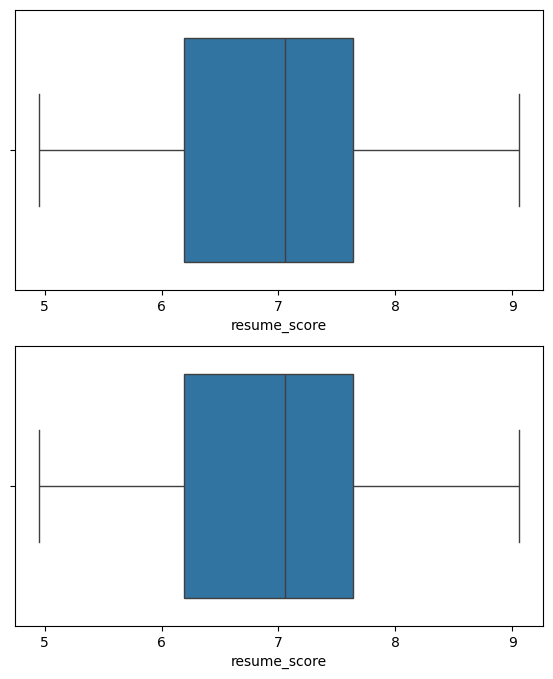

In [ ]:
plt.figure(figsize= (15, 8))

plt.subplot(222)
sns.boxplot(x=df['resume_score'])

plt.subplot(224)
sns.boxplot(x=new_df_cap['resume_score'])

plt.show()

# Titanic

In [ ]:
ti_df = pd.read_csv('/content/titanic.csv')

In [ ]:
ti_df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [ ]:
ti_df['Age'].describe()

,Age
count,332.000000
mean,30.272590
std,14.181209
min,0.170000
25%,21.000000
50%,27.000000
75%,39.000000
max,76.000000


<Axes: xlabel='Age'>

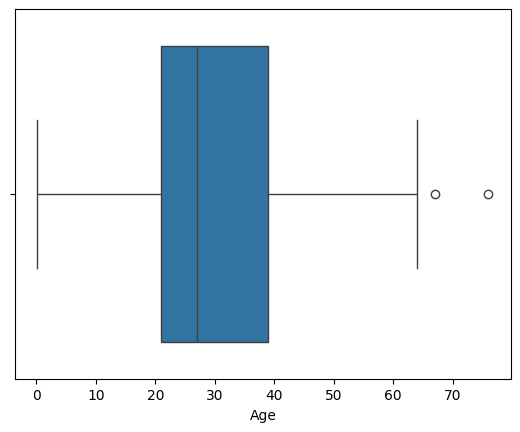

In [ ]:
sns.boxplot(x=ti_df['Age'])

In [ ]:
percentile25 = ti_df['Age'].quantile(0.25)
percentile75 = ti_df['Age'].quantile(0.75)

In [ ]:
percentile25

np.float64(21.0)

In [ ]:
percentile75

np.float64(39.0)

In [ ]:
IQR = percentile75 - percentile25
IQR

np.float64(18.0)

In [ ]:
upper_limit = percentile75 + 1.5*IQR
upper_limit

np.float64(66.0)

In [ ]:
lower_limit = percentile25 - 1.5*IQR
lower_limit

np.float64(-6.0)

# Finding Outliers

In [ ]:
ti_df[ti_df['Age']>upper_limit]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
81,973,0,1,"Straus, Mr. Isidor",male,67.0,1,0,PC 17483,221.7792,C55 C57,S
96,988,1,1,"Cavendish, Mrs. Tyrell William (Julia Florence...",female,76.0,1,0,19877,78.8500,C46,S


In [ ]:
ti_df[ti_df['Age']<lower_limit]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [ ]:
new_ti_df = ti_df[ti_df['Age']>upper_limit]

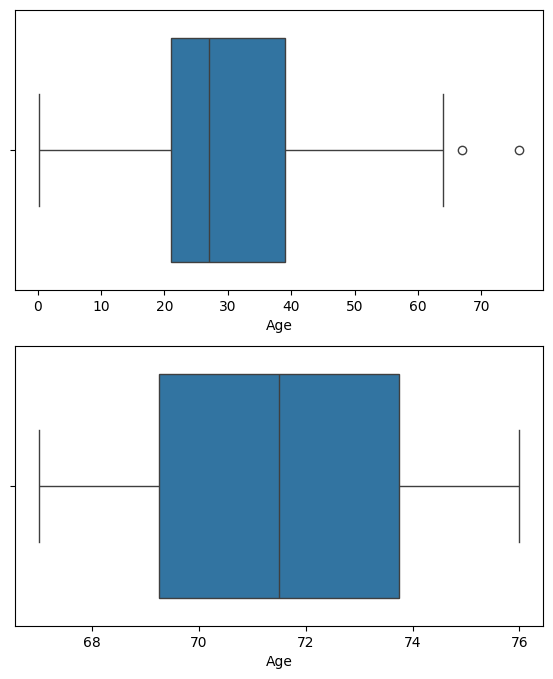

In [ ]:
plt.figure(figsize= (15, 8))

plt.subplot(222)
sns.boxplot(x=ti_df['Age'])

plt.subplot(224)
sns.boxplot(x=new_ti_df['Age'])

plt.show()

In [ ]:
new_df_ticap = ti_df.copy()

In [ ]:
new_df_ticap['Age'] = np.where(
    new_df_ticap['Age']>upper_limit,
    upper_limit,
    new_df_ticap['Age']
)

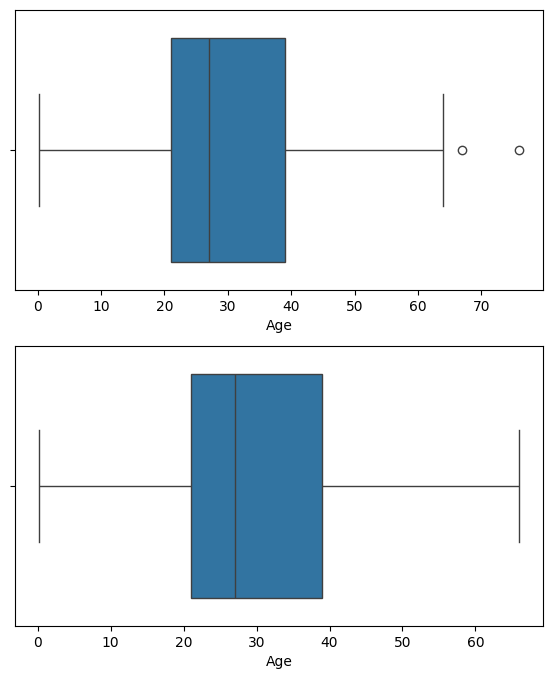

In [ ]:
plt.figure(figsize= (15, 8))

plt.subplot(222)
sns.boxplot(x=ti_df['Age'])

plt.subplot(224)
sns.boxplot(x=new_df_ticap['Age'])

plt.show()

what is API.
diff between rest api and fast api

what do you mean by api
create web page on fast api
> Add blockquote

